# EDA: Chest X-Ray Images (Pneumonia)
Dataset: Kermany et al., Cell 2018 (CC BY 4.0). Provenance, licence and
data-quality findings are in `data/README.md`. Images are not stored in the repo;
this notebook uses the CSVs in `data/` and the figures in `data/eda/`.

In [1]:
import pandas as pd
from IPython.display import Image, display

inv = pd.read_csv("../data/inventory_outer_with_patients.csv")
spl = pd.read_csv("../data/splits.csv")
print(len(inv), "images,", inv.patient_id.nunique(), "patients")

5856 images, 2790 patients


## Class counts: original vs proposed patient-level split

In [2]:
for col in ["orig_split", "split"]:
    print(col)
    print(spl.groupby([col, "label"]).size().unstack().reindex(["train", "val", "test"]), "\n")

orig_split
label       NORMAL  PNEUMONIA
orig_split                   
train         1341       3875
val              8          8
test           234        390 

split
label  NORMAL  PNEUMONIA
split                   
train    1109       2991
val       237        641
test      237        641 



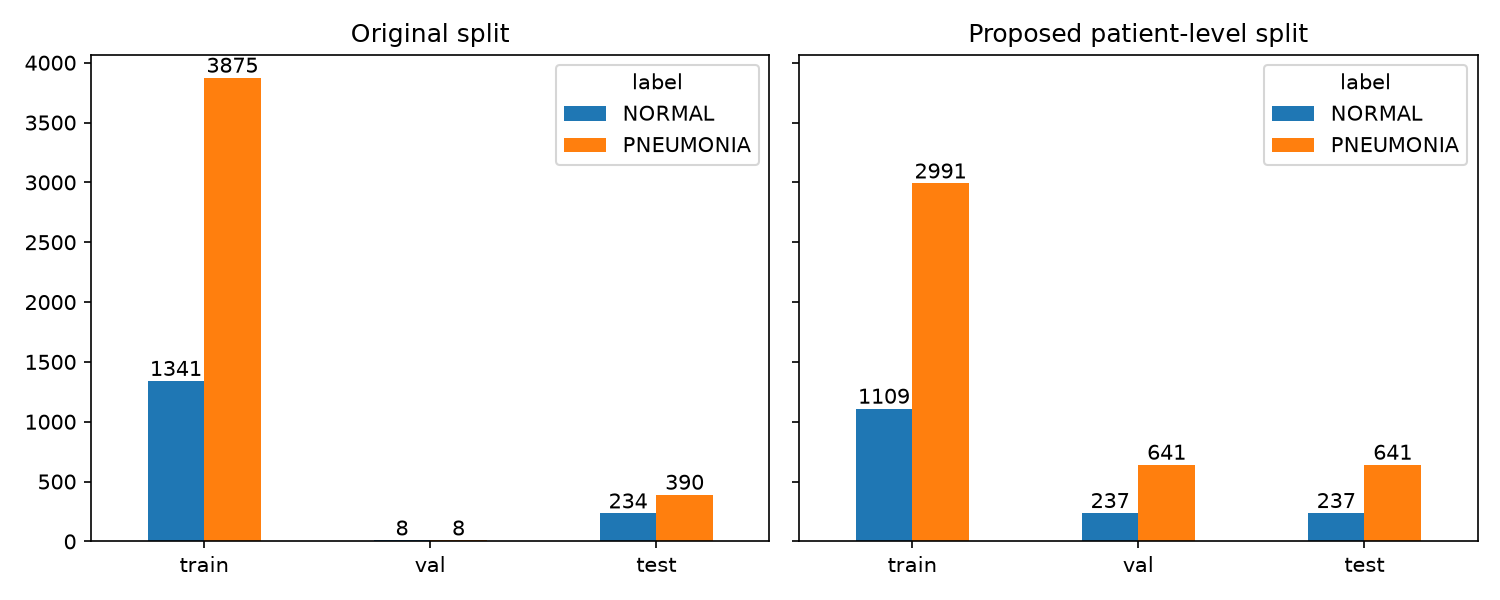

In [3]:
display(Image("../data/eda/class_distribution.png"))

## Image size and colour mode, by class

In [4]:
print(inv.groupby("label")[["width", "height"]].median())
print(pd.crosstab(inv.label, inv["mode"]))
print(inv[["width", "height"]].describe().round(0))

            width  height
label                    
NORMAL     1654.0  1323.0
PNEUMONIA  1160.0   776.0
mode          L  RGB
label               
NORMAL     1583    0
PNEUMONIA  3990  283
        width  height
count  5856.0  5856.0
mean   1328.0   971.0
std     364.0   383.0
min     384.0   127.0
25%    1056.0   688.0
50%    1281.0   888.0
75%    1560.0  1187.0
max    2916.0  2713.0


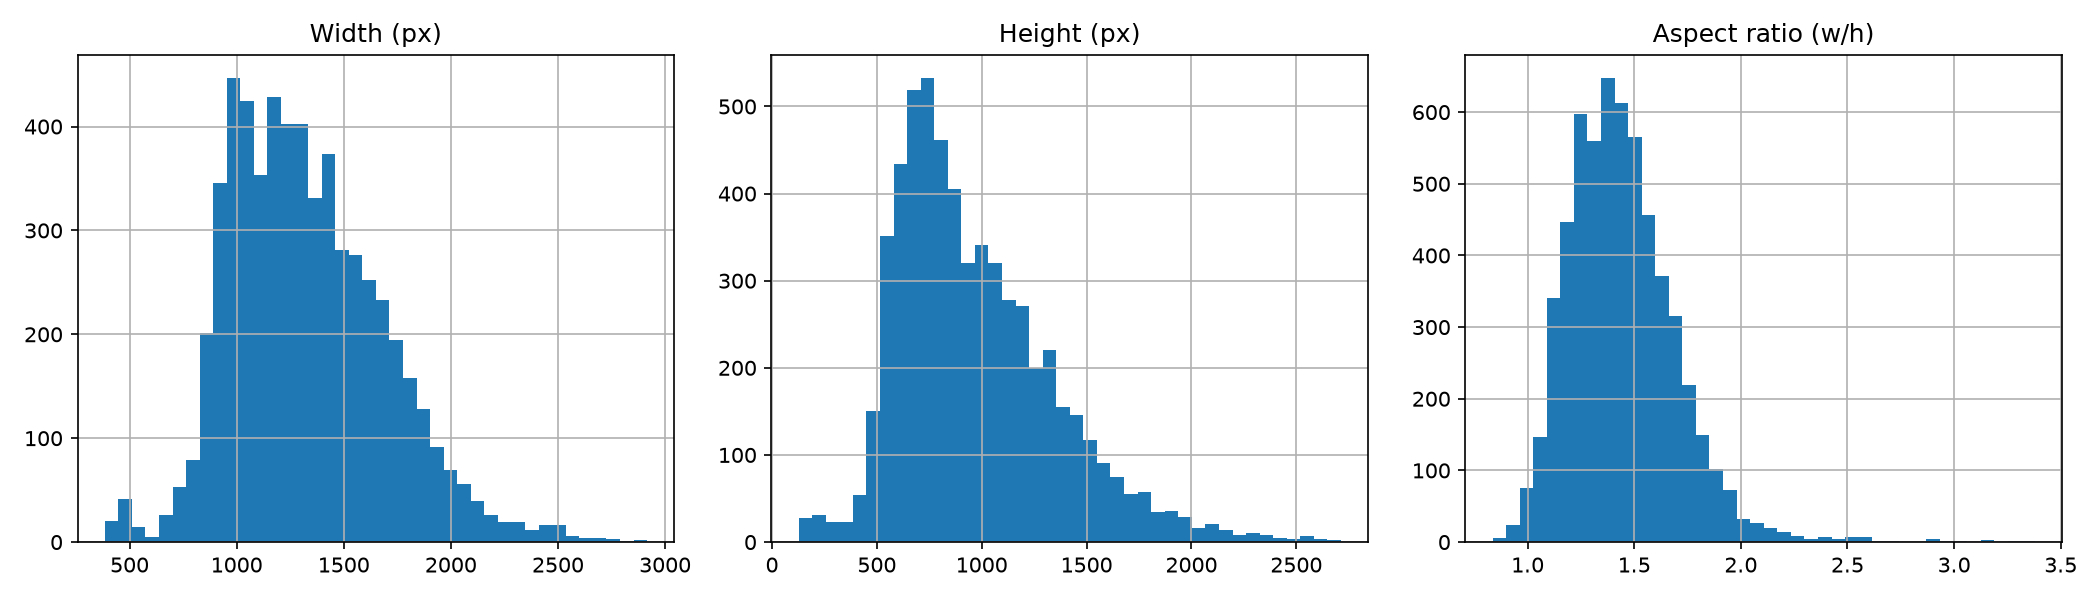

In [5]:
display(Image("../data/eda/image_sizes.png"))

## Patient overlap in the original split

In [6]:
n = spl.groupby("patient_id").orig_split.nunique()
leak = n[n > 1].index
lp = spl[spl.patient_id.isin(leak)].drop_duplicates("patient_id")
print("Patients in >1 original split, by label:")
print(lp.groupby("label").size())
print("Patients in >1 PROPOSED split:", (spl.groupby("patient_id").split.nunique() > 1).sum())

Patients in >1 original split, by label:
label
NORMAL        94
PNEUMONIA    170
dtype: int64
Patients in >1 PROPOSED split: 0


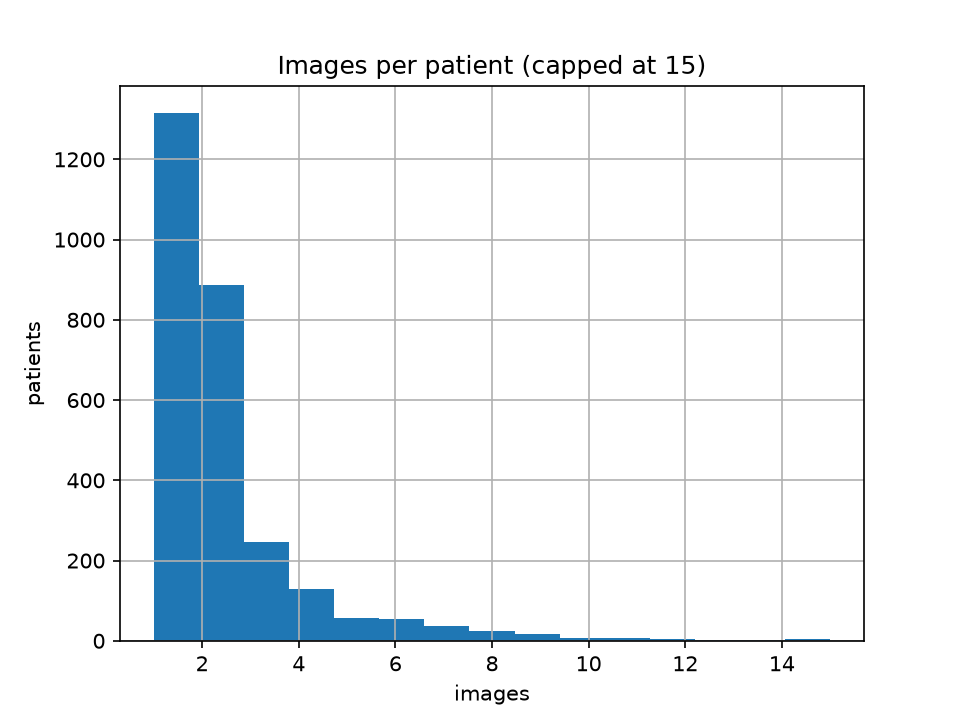

In [7]:
display(Image("../data/eda/images_per_patient.png"))

## Representative images (4 per class, random_state=42)

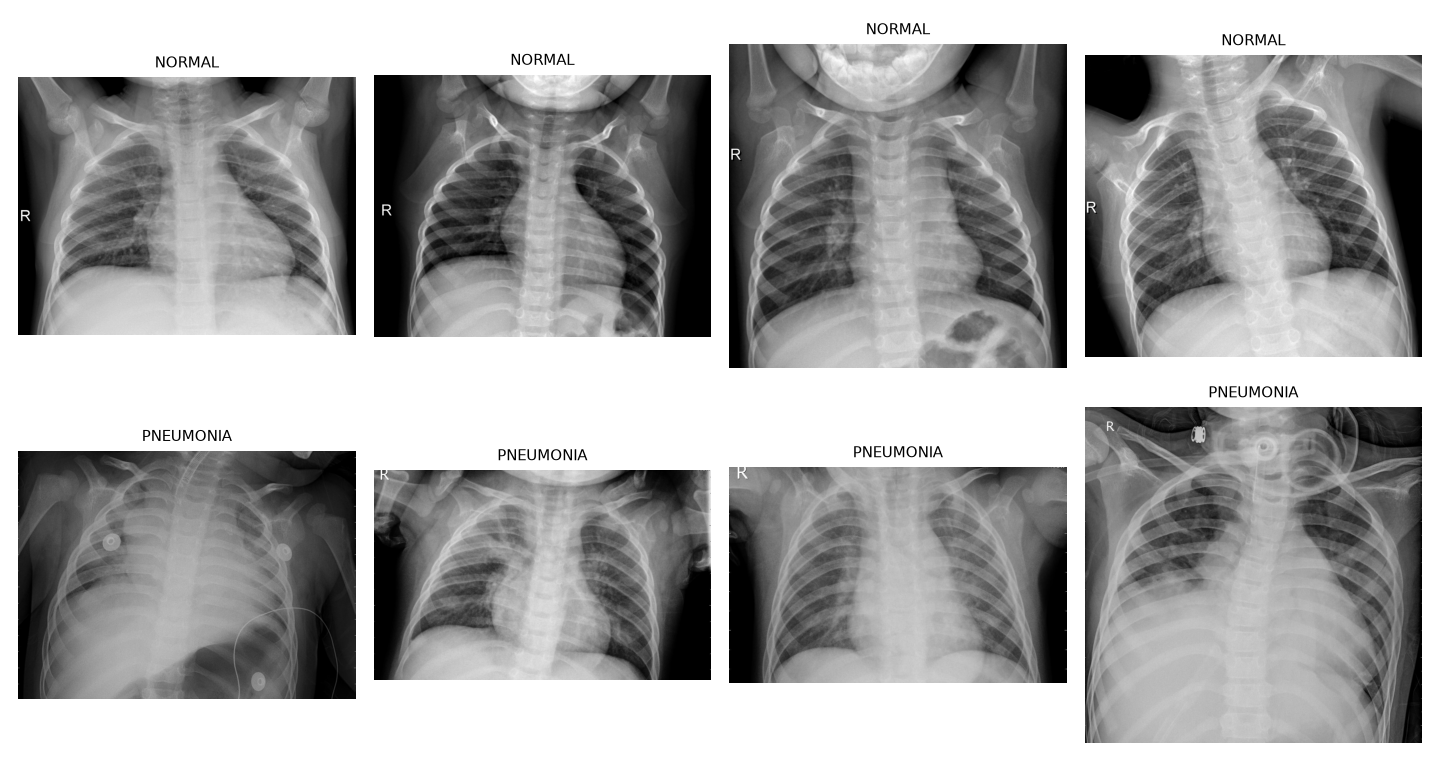

In [8]:
display(Image("../data/eda/sample_images.png"))

## Conclusions (observed in this dataset)
- 5,856 unique images from 2,790 patient IDs; 0 corrupt files; the zip also holds an
  identical nested copy, excluded from analysis.
- Classes are imbalanced, about 2.7:1 PNEUMONIA to NORMAL, and the proposed split
  keeps that ratio in train, val and test.
- Image sizes vary widely (width 384-2,916 px, height 127-2,713 px) and differ by
  class (median 1654x1323 px NORMAL vs 1160x776 px PNEUMONIA).
- 283 images (4.8%) are RGB, all PNEUMONIA; the rest are grayscale.
- A single height threshold classifies 84.8% of images correctly vs a 73.0%
  majority baseline (full dataset, no held-out set): size is a possible shortcut.
- The original split is not patient-level: 170 pneumonia patient IDs appear in both
  train and test. 94 normal IDs also appear in more than one split, but may be ID
  collisions between two filename series (unconfirmed).
- The proposed split has 0 patients in more than one split (`verify_splits.py` PASS).